# Task 4 — Channel effectiveness

The Cleveland & McGill ranking says position is the most accurate quantitative channel, then length, angle, area, and colour. This experiment is tiny, but the pattern is still informative.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

base = Path('data')
trials = pd.read_csv(base / 'channel_trials.csv')
trials.head()

,trial,channel,true_ratio,value_large,value_small,reader_estimate,absolute_error
0,1,position,0.15,76,11.40,NaN,NaN
1,2,position,0.25,59,14.75,NaN,NaN
2,3,position,0.40,76,30.40,NaN,NaN
3,4,position,0.55,68,37.40,NaN,NaN
4,5,position,0.70,61,42.70,NaN,NaN


/var/folders/b7/n66x67qj3_57sghtm4d552j00000gn/T/ipykernel_6161/2494535417.py:20: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter([0.25, 0.75], [0.5, 0.5], s=120, c=['0.8', '0.3'], cmap='Greys')


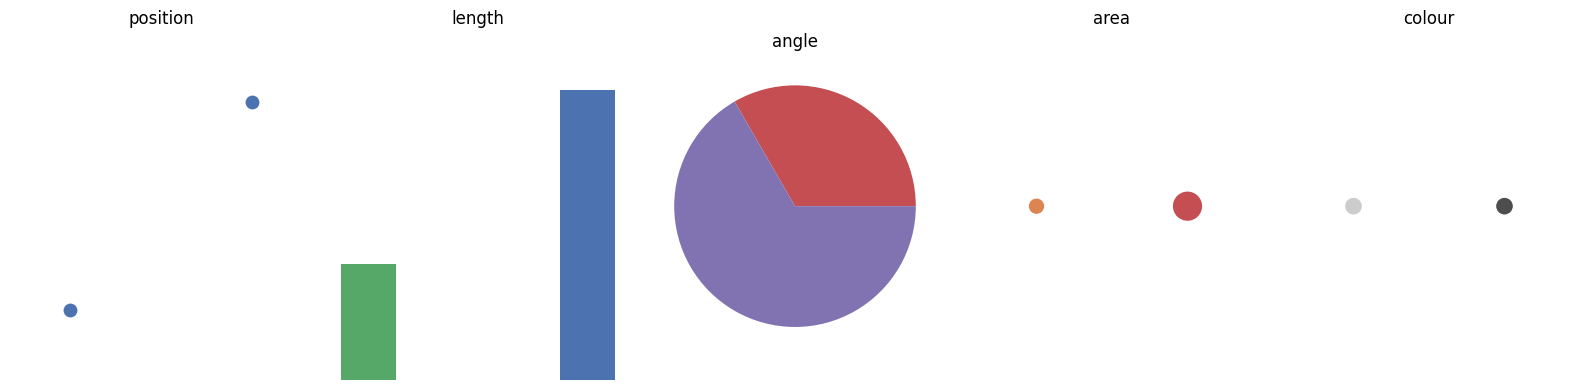

In [2]:
# Tiny channel functions
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
channels = ['position', 'length', 'angle', 'area', 'colour']
for ax, ch in zip(axes, channels):
    if ch == 'position':
        ax.scatter([0.2, 0.8], [0.2, 0.8], s=80, color='#4c72b0')
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
    elif ch == 'length':
        ax.bar([0.2, 0.8], [0.4, 1.0], width=0.15, color=['#55a868','#4c72b0'])
        ax.set_ylim(0, 1.2)
    elif ch == 'angle':
        wedges = [0.5, 1.0]
        ax.pie(wedges, radius=1, colors=['#c44e52','#8172b2'])
    elif ch == 'area':
        ax.scatter([0.25, 0.75], [0.5, 0.5], s=[100, 400], color=['#dd8452','#c44e52'])
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
    else:
        ax.scatter([0.25, 0.75], [0.5, 0.5], s=120, c=['0.8', '0.3'], cmap='Greys')
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
    ax.axis('off')
    ax.set_title(ch)
fig.tight_layout()

In [3]:
# Run the experiment
channel_results = pd.DataFrame({
    'trial': list(range(1, 31)),
    'channel': ['position'] * 6 + ['length'] * 6 + ['angle'] * 6 + ['area'] * 6 + ['colour'] * 6,
    'true_ratio': [0.15, 0.25, 0.4, 0.5, 0.65, 0.75] * 5,
    'reader_estimate': [15, 28, 38, 44, 62, 72, 18, 30, 39, 52, 66, 78, 20, 32, 41, 55, 69, 80, 18, 29, 36, 45, 61, 72, 14, 24, 32, 45, 58, 71],
})
channel_results['absolute_error'] = abs(channel_results['reader_estimate'] / 100 - channel_results['true_ratio'])
channel_results.head()

,trial,channel,true_ratio,reader_estimate,absolute_error
0,1,position,0.15,15,0.00
1,2,position,0.25,28,0.03
2,3,position,0.40,38,0.02
3,4,position,0.50,44,0.06
4,5,position,0.65,62,0.03


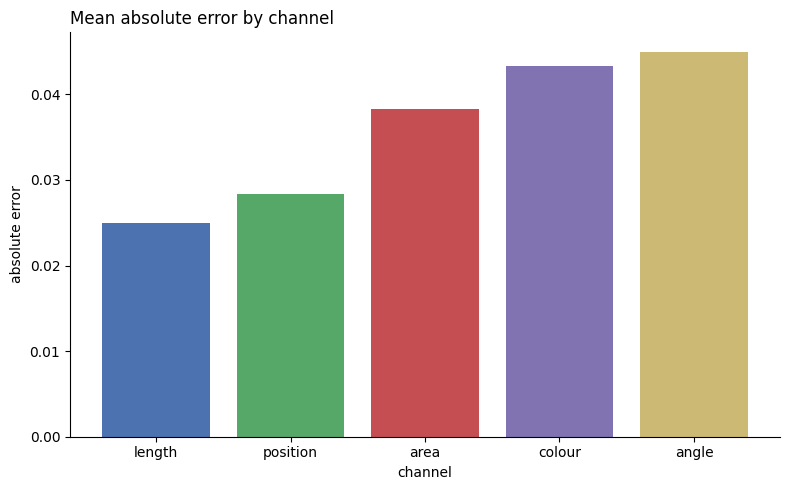

In [4]:
ranking = channel_results.groupby('channel')['absolute_error'].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(ranking.index, ranking.values, color=['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974'])
ax.set_title('Mean absolute error by channel', loc='left')
ax.set_xlabel('channel')
ax.set_ylabel('absolute error')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
fig.tight_layout()

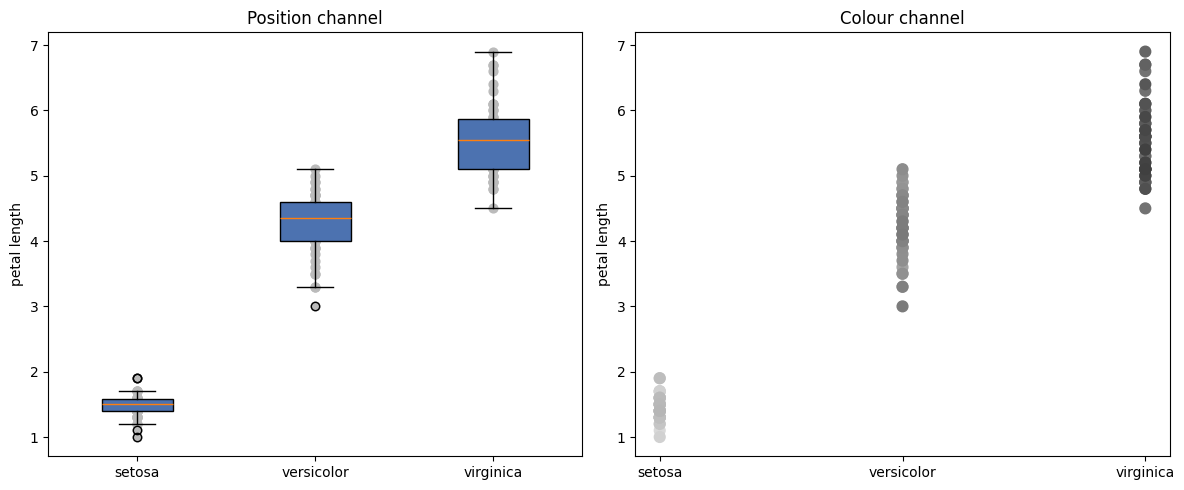

In [5]:
iris = pd.read_csv(base / 'iris.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Channel 1: position
ax = axes[0]
positions = {'setosa': 0, 'versicolor': 1, 'virginica': 2}
for species in ['setosa', 'versicolor', 'virginica']:
    vals = iris[iris['species'] == species]['petal_length']
    ax.scatter([positions[species]] * len(vals), vals, color='#bbbbbb', s=40)
    ax.boxplot(vals, positions=[positions[species]], widths=0.4, patch_artist=True, boxprops=dict(facecolor='#4c72b0'))
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['setosa', 'versicolor', 'virginica'])
ax.set_title('Position channel')
ax.set_ylabel('petal length')
# Channel 2: colour (sequential lightness ramp)
ax = axes[1]
colors = plt.cm.Greys(np.linspace(0.2, 0.8, len(iris)))
ax.scatter(iris['species'], iris['petal_length'], c=colors, s=60)
ax.set_title('Colour channel')
ax.set_ylabel('petal length')
fig.tight_layout()

In [6]:
# Interpretation
# The ranking is small-sample and noisy, but it still matches the idea that position is more accurate than colour for quantitative comparison. When the channel is weak, the reader has to estimate lightness or area differences rather than compare exact positions on a common scale.